# EDA GTSRB — Phân loại biển báo giao thông

Khảo sát dữ liệu gốc trước khi huấn luyện CNN cơ sở, CNN cải tiến và VGG16.

**Nội dung:** kiểm tra metadata và ảnh lỗi, phân bố 43 lớp, kích thước và ROI, độ sáng/độ tương phản, ảnh trùng pixel và nguy cơ rò rỉ khi chia validation.

**Chạy:** chọn Python kernel, chạy **Run All** theo thứ tự. Cần `numpy`, `pandas`, `matplotlib`, `Pillow`, `tqdm`, `IPython` và `ipykernel`. Nếu thiếu, chạy `%pip install numpy pandas matplotlib pillow tqdm ipykernel` trong một ô riêng. Quét toàn bộ hơn 51.000 ảnh có thể mất vài phút.

**Đường dẫn:** dữ liệu `data/raw/gtsrb`; kết quả `outputs/eda/`. Notebook không sửa dữ liệu gốc và chưa chia validation hay huấn luyện mô hình.

Nguồn: [GTSRB trên Kaggle](https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign).

## Chạy trên Google Colab

Chạy ô thiết lập (ô có `find_root()`) trước các ô phân tích. Khi chưa có dữ liệu,
notebook tự tải GTSRB từ Kaggle vào `/content/data/raw/gtsrb` (cần kết nối mạng).
Kết quả trên Colab được ghi vào `/content/outputs/eda/`. Các tệp trong `/content`
là tạm thời; cần tải kết quả về hoặc sao lưu trước khi phiên Colab kết thúc.

Tệp dữ liệu ở ổ D: trên máy cá nhân không tự xuất hiện trên máy Colab.


In [4]:
!nvidia-smi

Sun Nov  1 08:27:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display, Markdown
import hashlib
import json
import platform
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageOps
from tqdm.auto import tqdm

SEED = 42
FULL_IMAGE_SCAN = True  # False: chạy thử nhanh bằng cách lấy mẫu theo lớp.
QUICK_SAMPLES_PER_CLASS = 20
IMAGE_SCAN_WORKERS = 8  # Song song các tác vụ đọc ảnh; giảm xuống 1 nếu ổ đĩa quá tải.
DARK_THRESHOLD, BRIGHT_THRESHOLD, LOW_CONTRAST_THRESHOLD = 40, 215, 20

def find_root():
    current = Path.cwd().resolve()
    for p in [current, *current.parents]:
        if (p / 'data/raw/gtsrb/Train.csv').is_file():
            return p

    # Colab dùng máy riêng, không truy cập được ổ D: trên máy Windows.
    try:
        import google.colab
    except ImportError:
        raise FileNotFoundError(
            'Không tìm thấy data/raw/gtsrb/Train.csv. '
            'Trên máy cá nhân, mở notebook trong thư mục dự án có dữ liệu. '
            'Trên Colab, chạy lại ô thiết lập để tự tải dữ liệu.'
        ) from None

    import subprocess
    import sys
    root = Path('/content')
    destination = root / 'data/raw/gtsrb'
    destination.mkdir(parents=True, exist_ok=True)
    print('Colab chưa có dữ liệu. Đang chuẩn bị kagglehub và tải GTSRB (~612 MB)...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', 'kagglehub'])
    import kagglehub
    kagglehub.dataset_download(
        'meowmeowmeowmeowmeow/gtsrb-german-traffic-sign',
        output_dir=str(destination),
    )
    expected = ['Train.csv', 'Test.csv', 'Meta.csv', 'Train', 'Test', 'Meta']
    missing = [name for name in expected if not (destination / name).exists()]
    if missing:
        raise FileNotFoundError(f'Tải dữ liệu chưa đầy đủ; thiếu: {missing}. Chạy lại ô thiết lập.')
    print('Dữ liệu đã sẵn sàng:', destination)
    return root

ROOT = find_root()
DATA_DIR = ROOT / 'data/raw/gtsrb'
OUT = ROOT / 'outputs/eda'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__, 'pillow': PIL.__version__}
print('Dữ liệu:', DATA_DIR, '\nKết quả:', OUT)
print('Quét đầy đủ:', FULL_IMAGE_SCAN, '\nPhiên bản:', VERSIONS)

def savefig(name):
    plt.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')


Colab chưa có dữ liệu. Đang chuẩn bị kagglehub và tải GTSRB (~612 MB)...


100%|██████████| 612M/612M [00:09<00:00, 65.7MB/s] 

Extracting files...


Dữ liệu đã sẵn sàng: /content/data/raw/gtsrb
Dữ liệu: /content/data/raw/gtsrb 
Kết quả: /content/outputs/eda
Quét đầy đủ: True 
Phiên bản: {'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'pillow': '11.3.0'}


## 1. Đọc metadata và kiểm tra cấu trúc

Train/Test CSV chứa ClassId, đường dẫn, kích thước và ROI; Meta CSV chứa mô tả các lớp. Tên tiếng Anh được ánh xạ theo ClassId chuẩn của GTSRB.

Giữ test độc lập. Thống kê tổng quát của test trong EDA chỉ dùng kiểm tra tính toàn vẹn và mô tả dữ liệu; không dùng để chọn siêu tham số, augmentation hay mô hình.


In [6]:
CLASS_NAMES = [
 'Speed limit (20 km/h)', 'Speed limit (30 km/h)', 'Speed limit (50 km/h)',
 'Speed limit (60 km/h)', 'Speed limit (70 km/h)', 'Speed limit (80 km/h)',
 'End of speed limit (80 km/h)', 'Speed limit (100 km/h)', 'Speed limit (120 km/h)',
 'No passing', 'No passing for vehicles over 3.5 t', 'Right-of-way at next intersection',
 'Priority road', 'Yield', 'Stop', 'No vehicles', 'Vehicles over 3.5 t prohibited',
 'No entry', 'General caution', 'Dangerous curve left', 'Dangerous curve right',
 'Double curve', 'Bumpy road', 'Slippery road', 'Road narrows on the right', 'Road work',
 'Traffic signals', 'Pedestrians', 'Children crossing', 'Bicycles crossing',
 'Beware of ice/snow', 'Wild animals crossing', 'End of all speed and passing limits',
 'Turn right ahead', 'Turn left ahead', 'Ahead only', 'Go straight or right',
 'Go straight or left', 'Keep right', 'Keep left', 'Roundabout mandatory',
 'End of no passing', 'End of no passing for vehicles over 3.5 t']
CLASS_LOOKUP = dict(enumerate(CLASS_NAMES))
train = pd.read_csv(DATA_DIR / 'Train.csv')
test = pd.read_csv(DATA_DIR / 'Test.csv')
meta = pd.read_csv(DATA_DIR / 'Meta.csv')
required = {'Path', 'ClassId', 'Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2'}
for name, df in [('Train', train), ('Test', test)]:
    assert required.issubset(df.columns), f'{name}: thiếu cột {required - set(df.columns)}'
    assert df[list(required)].notna().all().all(), f'{name}: metadata bắt buộc có giá trị thiếu'
    assert df['ClassId'].between(0, 42).all() and (df['ClassId'] % 1 == 0).all(), 'Nhãn không hợp lệ'
    df['ClassId'] = df['ClassId'].astype(int)
    df['Split'] = name
    df['ClassName'] = df['ClassId'].map(CLASS_LOOKUP)
assert {'Path', 'ClassId'}.issubset(meta.columns)
assert set(meta['ClassId']) == set(range(43)), 'Meta cần đủ 43 lớp'
data = pd.concat([train, test], ignore_index=True)
pd.DataFrame({'ClassId': range(43), 'ClassName': CLASS_NAMES}).to_csv(OUT / 'class_mapping.csv', index=False)
overview = pd.DataFrame([{'Split': name, 'Images': len(df), 'Classes': df['ClassId'].nunique()}
                         for name, df in [('Train', train), ('Test', test), ('Meta', meta)]])
display(overview)
display(train.head())
display(meta.sort_values('ClassId').head())
overview.to_csv(OUT / 'dataset_overview.csv', index=False)


,Split,Images,Classes
0,Train,39209,43
1,Test,12630,43
2,Meta,43,43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,Split,ClassName
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,Train,Dangerous curve right
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,Train,Dangerous curve right
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,Train,Dangerous curve right
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,Train,Dangerous curve right
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,Train,Dangerous curve right


,Path,ClassId,ShapeId,ColorId,SignId
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
13,Meta/2.png,2,1,0,3.29
23,Meta/3.png,3,1,0,3.29
34,Meta/4.png,4,1,0,3.29


In [7]:
# Lập danh sách tệp một lần thay vì gọi exists() riêng cho từng dòng.
inventory = {p.relative_to(DATA_DIR).as_posix().casefold() for p in DATA_DIR.rglob('*') if p.is_file()}
checks = []
for name, df in [('Train', train), ('Test', test), ('Meta', meta)]:
    paths = df['Path'].astype('string').str.replace('\\', '/', regex=False)
    safe = paths.map(lambda p: pd.notna(p) and not Path(str(p)).is_absolute() and '..' not in Path(str(p)).parts)
    exists = paths.map(lambda p: pd.notna(p) and str(p).casefold() in inventory)
    checks.append({'Split': name, 'MissingValues': int(df.isna().sum().sum()),
                   'DuplicatePathRows': int(paths.duplicated().sum()),
                   'InvalidPaths': int((~safe).sum()), 'MissingFiles': int((~exists).sum())})
    df.loc[~(safe & exists)].to_csv(OUT / f'{name.lower()}_invalid_paths.csv', index=False)
checks = pd.DataFrame(checks)
display(checks)
checks.to_csv(OUT / 'metadata_checks.csv', index=False)
assert checks[['InvalidPaths', 'MissingFiles']].to_numpy().sum() == 0, 'Cần xử lý đường dẫn lỗi trước khi tiếp tục'
assert checks['DuplicatePathRows'].sum() == 0, 'Cần xem lại các dòng trùng đường dẫn trước khi tiếp tục'
valid_size = data['Width'].gt(0) & data['Height'].gt(0)
valid_roi = (data['Roi.X1'].ge(0) & data['Roi.Y1'].ge(0)
             & data['Roi.X2'].ge(data['Roi.X1']) & data['Roi.Y2'].ge(data['Roi.Y1'])
             & data['Roi.X2'].le(data['Width']) & data['Roi.Y2'].le(data['Height']))
metadata_issues = data.loc[~valid_size | ~valid_roi]
metadata_issues.to_csv(OUT / 'metadata_anomalies.csv', index=False)
print('Dòng có kích thước hoặc ROI bất thường:', len(metadata_issues))
display(metadata_issues.head())

# Chỉ rõ cột và dòng thiếu metadata mô tả, thay vì chỉ đếm tổng.
missing_details = pd.concat([
    df.isna().sum().rename('MissingCount').rename_axis('Column').reset_index().assign(Split=name)
    for name, df in [('Train', train), ('Test', test), ('Meta', meta)]], ignore_index=True)
missing_details = missing_details.loc[missing_details['MissingCount'].gt(0)]
missing_details.to_csv(OUT / 'missing_values_by_column.csv', index=False)
display(missing_details)
display(meta.loc[meta.isna().any(axis=1)])
print('SignId/ShapeId/ColorId là metadata mô tả; nhãn phân loại sử dụng ClassId.')


,Split,MissingValues,DuplicatePathRows,InvalidPaths,MissingFiles
0,Train,0,0,0,0
1,Test,0,0,0,0
2,Meta,1,0,0,0


Dòng có kích thước hoặc ROI bất thường: 0


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,Split,ClassName


,Column,MissingCount,Split
24,SignId,1,Meta


,Path,ClassId,ShapeId,ColorId,SignId
24,Meta/30.png,30,0,0,NaN


SignId/ShapeId/ColorId là metadata mô tả; nhãn phân loại sử dụng ClassId.


## 2. Phân bố lớp và mất cân bằng

Thống kê số ảnh từng lớp và tỷ lệ trong mỗi tập. Chưa cân bằng dữ liệu ở bước EDA. Khi đánh giá mô hình, xem thêm macro-F1 và recall từng lớp thay vì chỉ dùng accuracy.


Tỷ lệ lớp nhiều nhất / ít nhất trong train: 10.71 lần


Split,Test,Train,ClassName,TrainPct,TestPct,TestMinusTrainPctPoints
ClassId,,,,,,
0,60,210,Speed limit (20 km/h),0.535591,0.475059,-0.060532
1,720,2220,Speed limit (30 km/h),5.661965,5.700713,0.038747
2,750,2250,Speed limit (50 km/h),5.738478,5.938242,0.199764
3,450,1410,Speed limit (60 km/h),3.596113,3.562945,-0.033168
4,660,1980,Speed limit (70 km/h),5.049861,5.225653,0.175792
5,630,1860,Speed limit (80 km/h),4.743809,4.988124,0.244315
6,150,420,End of speed limit (80 km/h),1.071183,1.187648,0.116466
7,450,1440,Speed limit (100 km/h),3.672626,3.562945,-0.109681
8,450,1410,Speed limit (120 km/h),3.596113,3.562945,-0.033168


5 lớp train ít mẫu nhất:


Split,ClassName,Train,Test
ClassId,,,
0,Speed limit (20 km/h),210,60
19,Dangerous curve left,210,60
37,Go straight or left,210,60
27,Pedestrians,240,60
32,End of all speed and passing limits,240,60


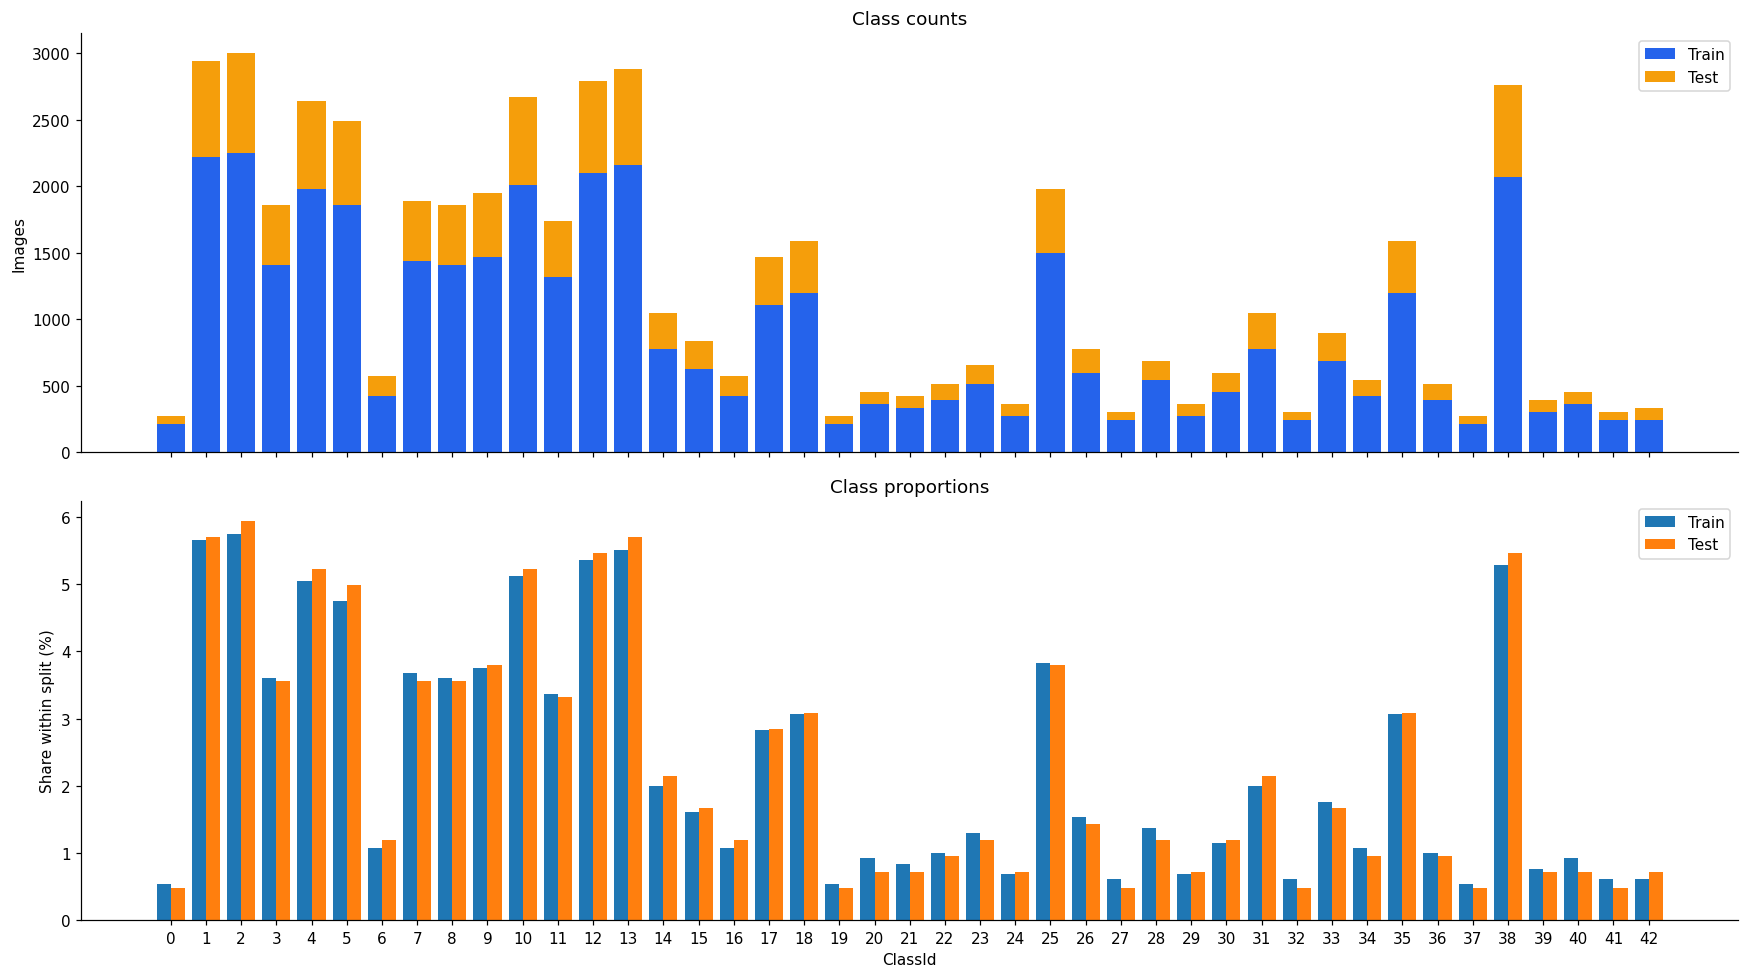

In [8]:
counts = data.groupby(['ClassId', 'Split']).size().unstack(fill_value=0).reindex(range(43), fill_value=0)
counts['ClassName'] = pd.Series(CLASS_LOOKUP)
for split in ['Train', 'Test']:
    counts[f'{split}Pct'] = counts[split] / counts[split].sum() * 100
counts['TestMinusTrainPctPoints'] = counts['TestPct'] - counts['TrainPct']
counts.to_csv(OUT / 'class_distribution.csv')
assert counts['Train'].gt(0).all(), 'Train thiếu ít nhất một lớp'
imbalance_ratio = counts['Train'].max() / counts['Train'].min()
print(f'Tỷ lệ lớp nhiều nhất / ít nhất trong train: {imbalance_ratio:.2f} lần')
display(counts)
print('5 lớp train ít mẫu nhất:')
display(counts.nsmallest(5, 'Train')[['ClassName', 'Train', 'Test']])
x = np.arange(43)
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
axes[0].bar(x, counts['Train'], label='Train', color='#2563eb')
axes[0].bar(x, counts['Test'], bottom=counts['Train'], label='Test', color='#f59e0b')
axes[0].set(ylabel='Images', title='Class counts')
axes[1].bar(x-.2, counts['TrainPct'], width=.4, label='Train')
axes[1].bar(x+.2, counts['TestPct'], width=.4, label='Test')
axes[1].set(xlabel='ClassId', ylabel='Share within split (%)', title='Class proportions')
axes[1].set_xticks(x)
for ax in axes: ax.legend()
plt.tight_layout()
savefig('01_class_distribution')
plt.show()


## 3. Quan sát các lớp và ảnh train

Meta chỉ là ảnh tham chiếu, không bổ sung vào train. Quan sát ký hiệu, màu sắc, nền và các lớp gần giống nhau. Hiển thị ảnh lớn trong biểu đồ không tăng độ phân giải thật.


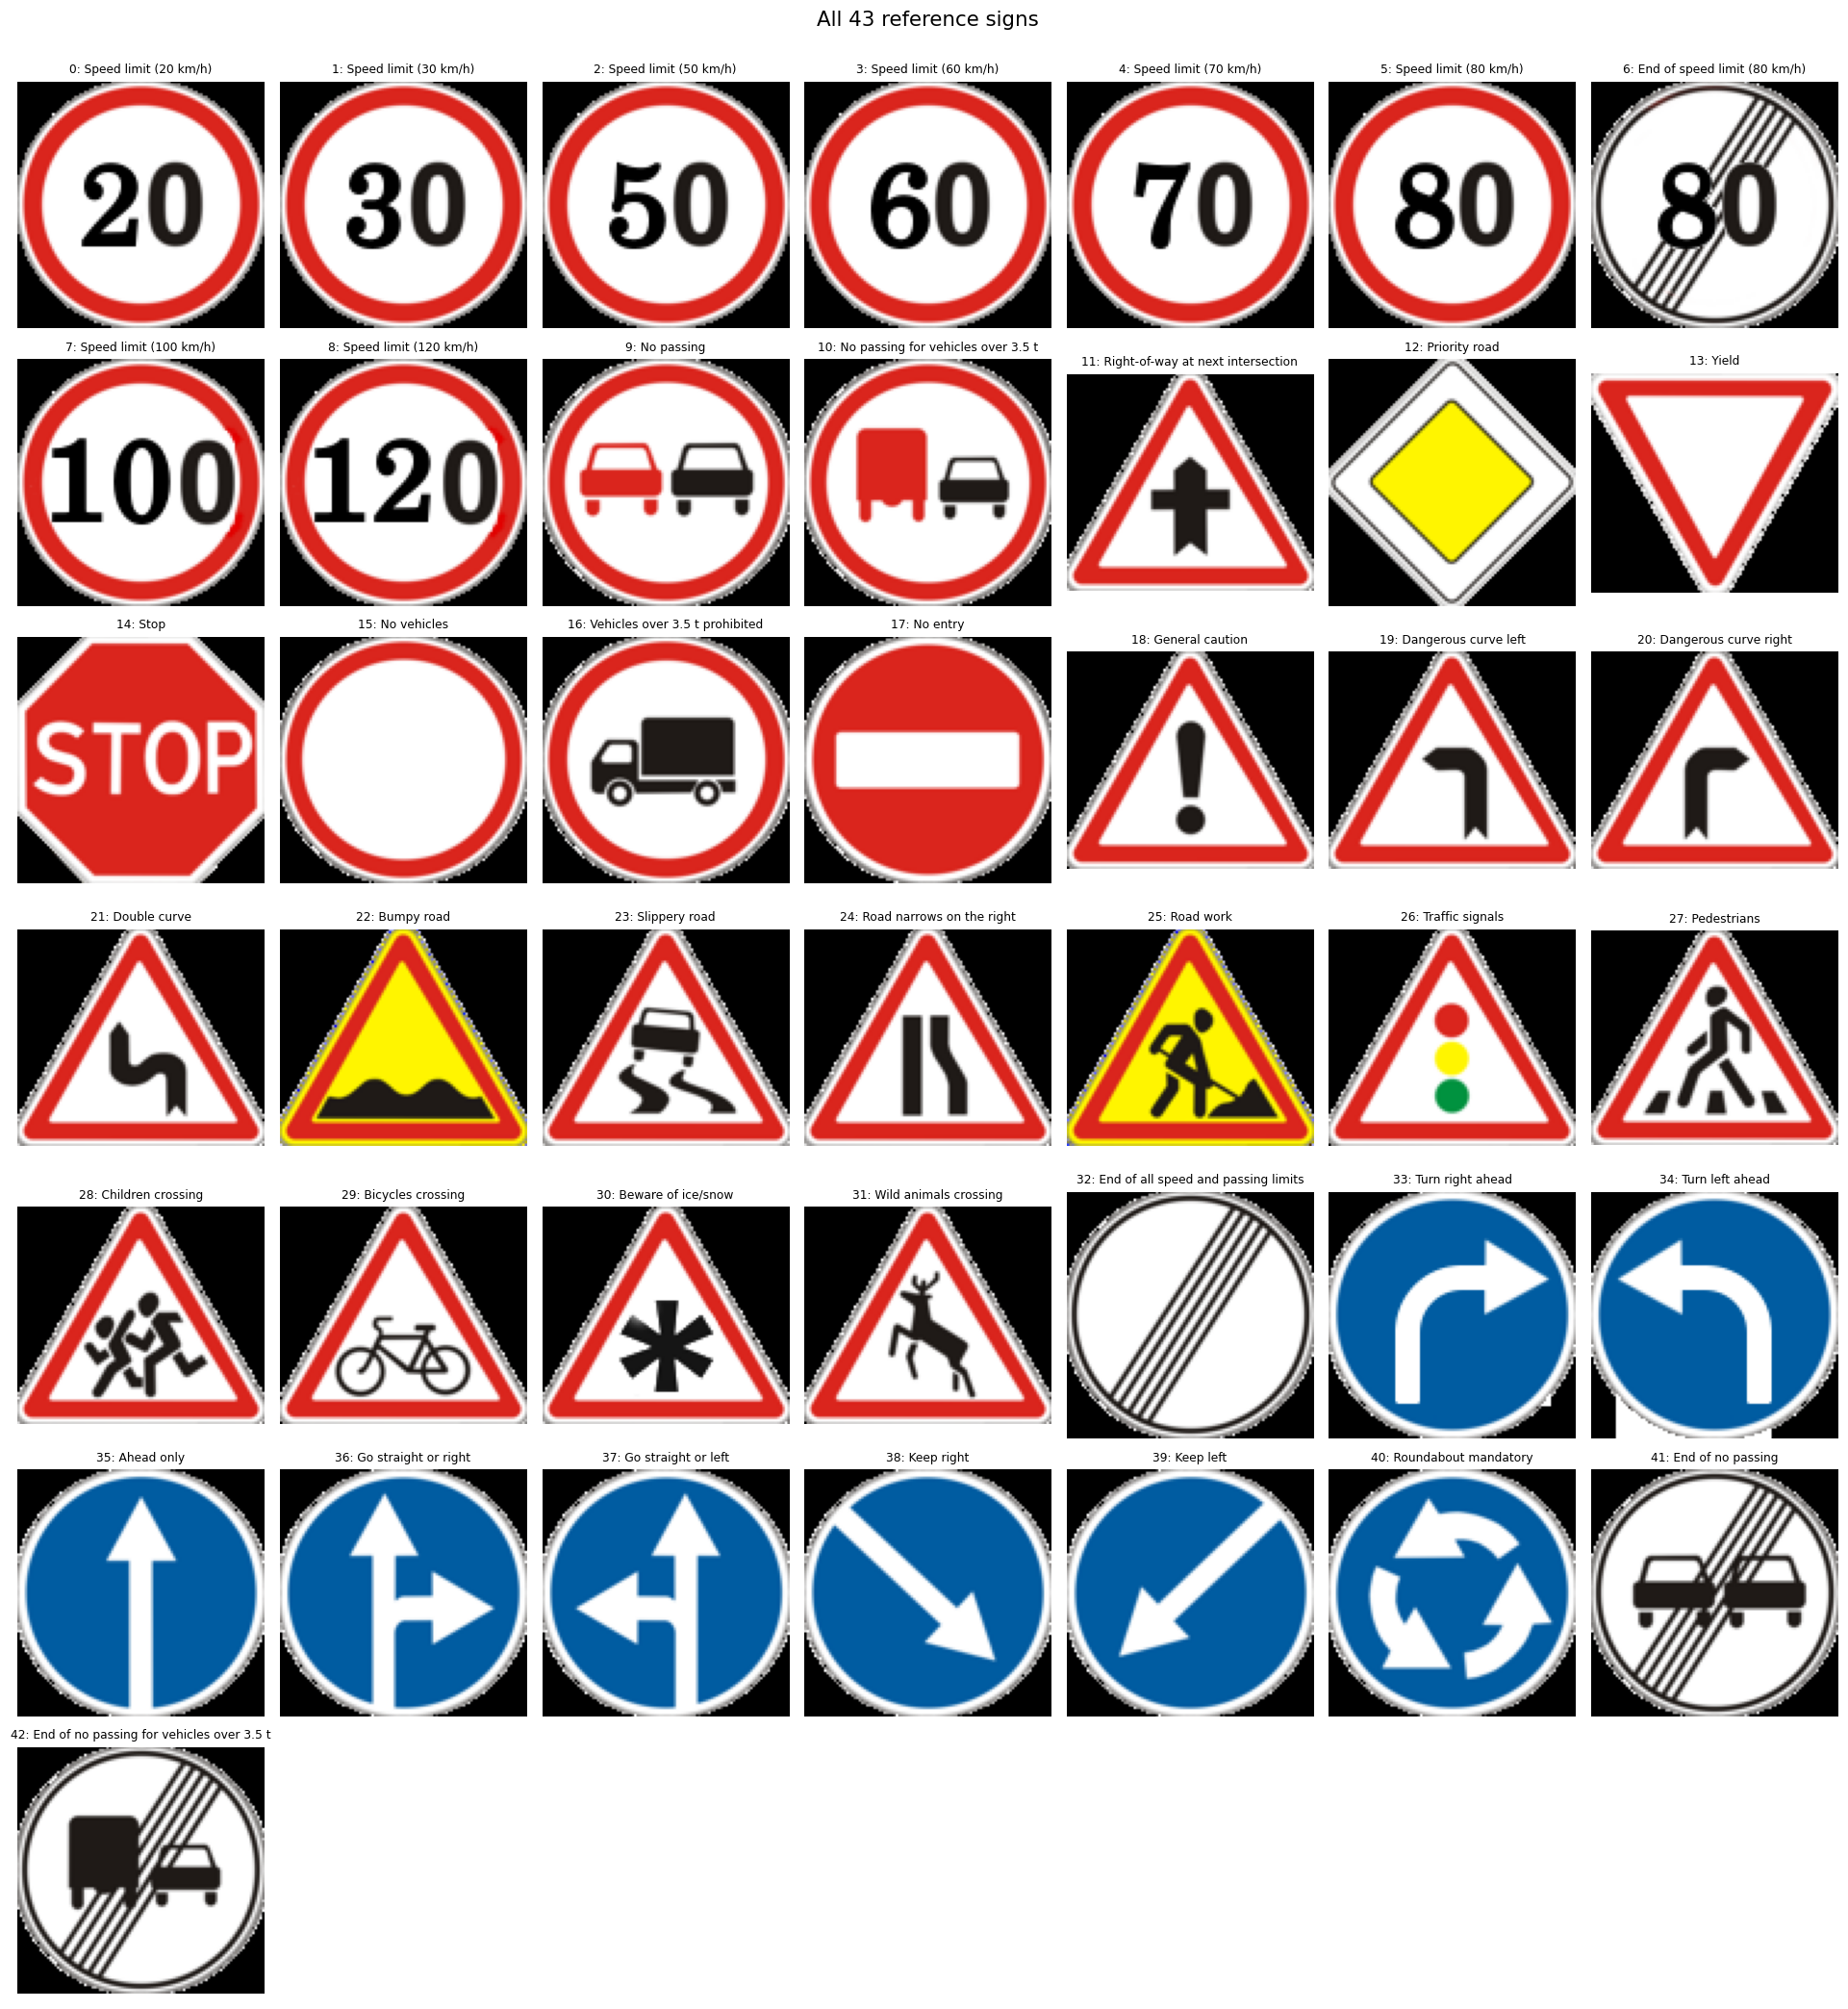

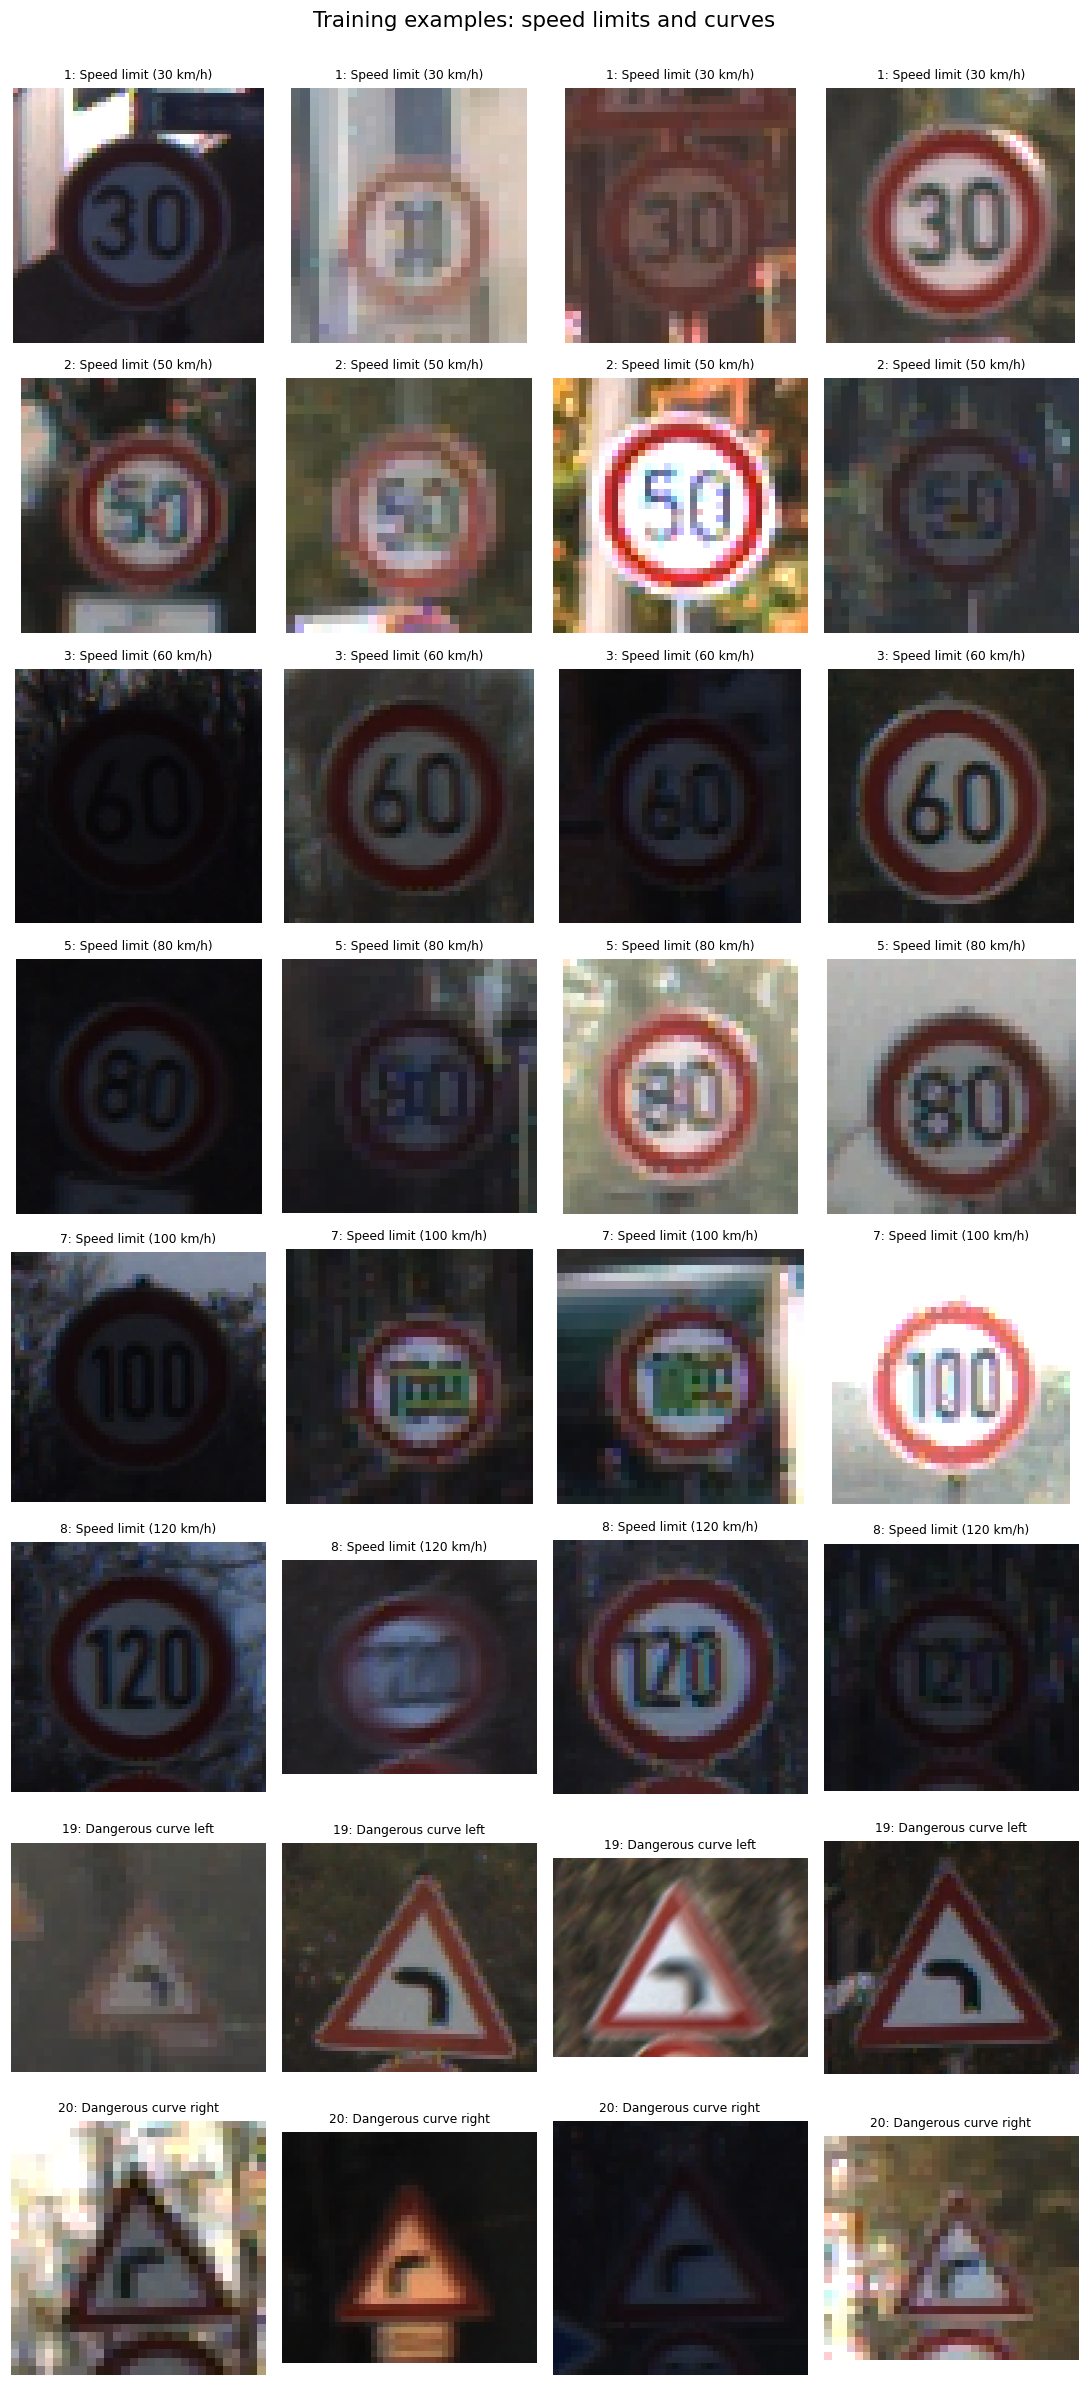

In [9]:
def image_grid(df, title, columns=6, output_name=None):
    if df.empty:
        print('Không có ảnh:', title)
        return
    rows = int(np.ceil(len(df) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns*2.5, rows*2.7), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, row in zip(axes.flat, df.itertuples(index=False)):
        try:
            with Image.open(DATA_DIR / row.Path) as image:
                ax.imshow(image.convert('RGB'))
            cid = int(row.ClassId)
            ax.set_title(f'{cid}: {CLASS_LOOKUP[cid]}', fontsize=8, wrap=True)
        except (OSError, ValueError) as exc:
            ax.set_title(type(exc).__name__, fontsize=8)
    fig.suptitle(title, fontsize=14, y=1.002)
    fig.tight_layout()
    if output_name: savefig(output_name)
    plt.show()

image_grid(meta.sort_values('ClassId'), 'All 43 reference signs', columns=7, output_name='02_all_classes')
examples = pd.concat([train[train['ClassId'].eq(cid)].sample(4, random_state=SEED)
                      for cid in [1, 2, 3, 5, 7, 8, 19, 20]], ignore_index=True)
image_grid(examples, 'Training examples: speed limits and curves', columns=4, output_name='03_train_examples')


## 4. Kích thước, tỷ lệ khung hình và ROI

Thống kê từ CSV, sẽ đối chiếu với ảnh thật trong bước quét. Ảnh rất nhỏ có thể thiếu chi tiết; resize thành hình vuông có thể gây biến dạng. Chưa chốt kích thước đầu vào ở bước này.


Width                                                        Height  \
         count       mean        std   min   25%   50%   75%    max    count   
Split                                                                          
Test   12630.0  50.507759  25.088483  25.0  34.0  43.0  58.0  266.0  12630.0   
Train  39209.0  50.835880  24.306933  25.0  35.0  43.0  58.0  243.0  39209.0   

                 ... AspectRatio               Area                            \
           mean  ...         75%       max    count         mean          std   
Split            ...                                                            
Test   50.36445  ...    1.035714  1.437500  12630.0  3125.009976  3930.957058   
Train  50.32893  ...    1.040816  1.417808  39209.0  3109.825525  3664.547028   

                                               
         min     25%     50%     75%      max  
Split                                          
Test   625.0  1190.0  1845.0  3306.0  61712.0  
Train  625.0  1190.0  1849.0  3360.0  54675.0  

[2 rows x 32 columns]

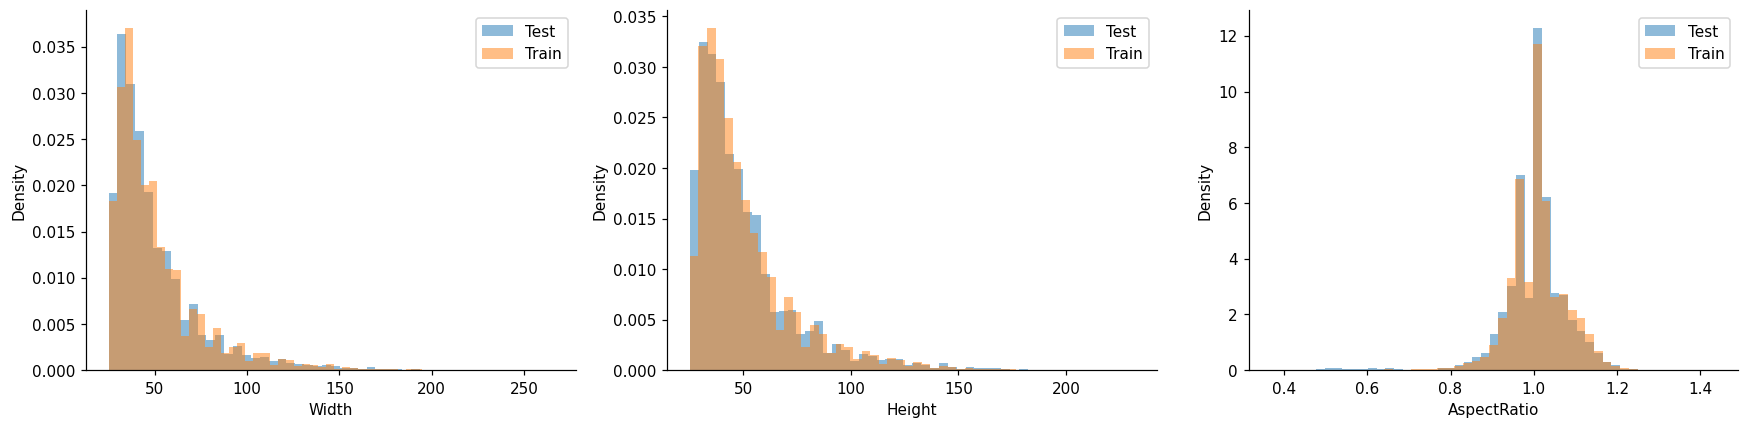

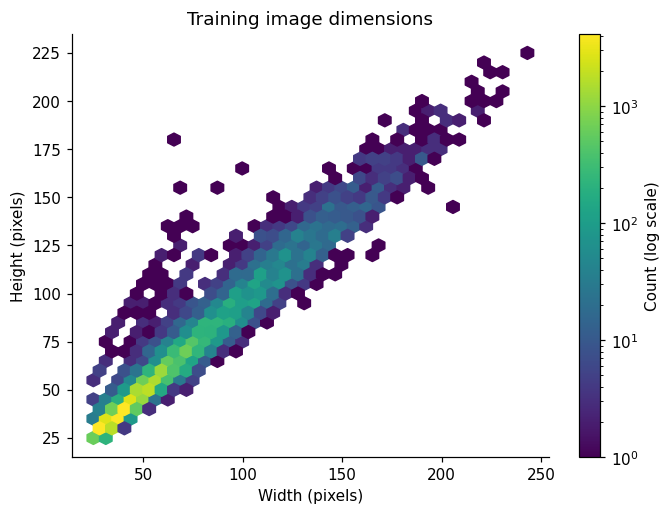

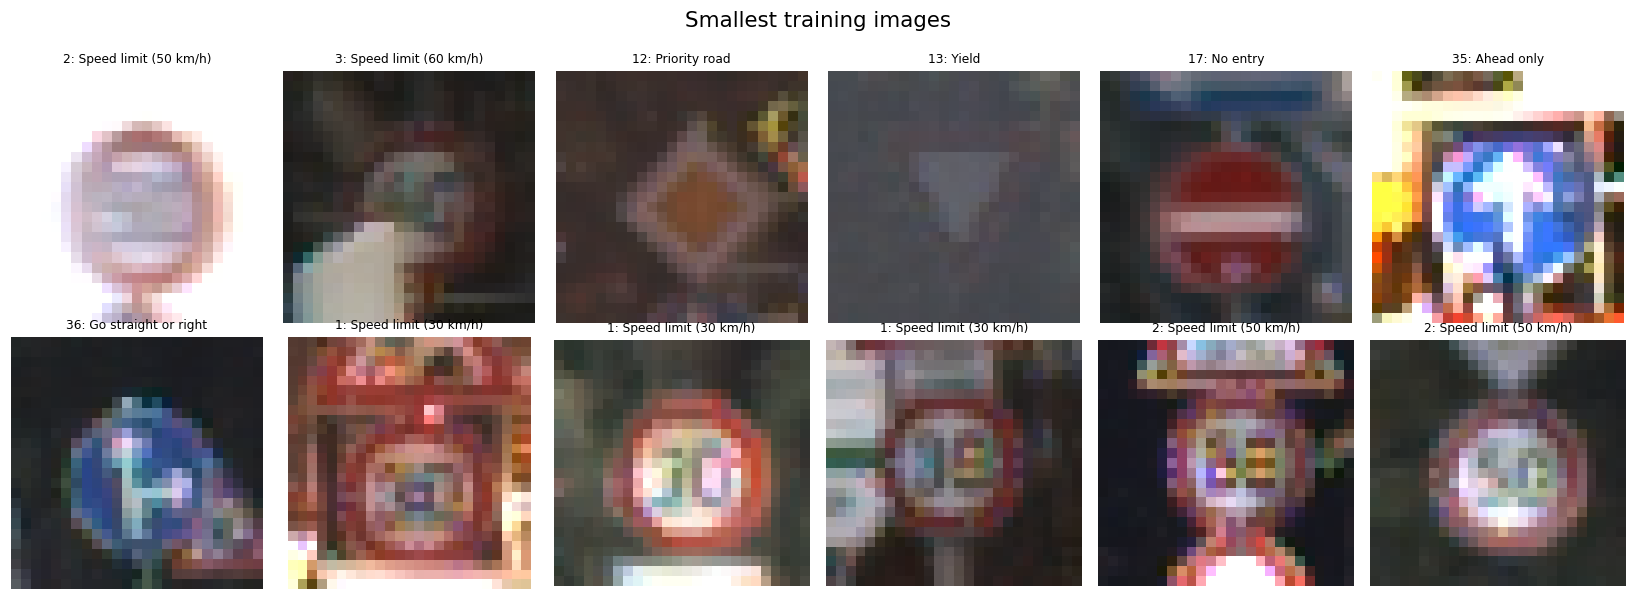

In [10]:
data['AspectRatio'] = data['Width'] / data['Height']
data['Area'] = data['Width'] * data['Height']
size_summary = data.groupby('Split')[['Width', 'Height', 'AspectRatio', 'Area']].describe()
size_summary.to_csv(OUT / 'size_summary.csv')
display(size_summary)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for split, df in data.groupby('Split'):
    for ax, feature in zip(axes, ['Width', 'Height', 'AspectRatio']):
        ax.hist(df[feature], bins=50, alpha=.5, density=True, label=split)
        ax.set(xlabel=feature, ylabel='Density')
for ax in axes: ax.legend()
plt.tight_layout()
savefig('04_image_sizes')
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
h = ax.hexbin(train['Width'], train['Height'], gridsize=35, mincnt=1, bins='log', cmap='viridis')
fig.colorbar(h, ax=ax, label='Count (log scale)')
ax.set(xlabel='Width (pixels)', ylabel='Height (pixels)', title='Training image dimensions')
savefig('05_width_height')
plt.show()
image_grid(train.assign(Area=train['Width']*train['Height']).nsmallest(12, 'Area'),
           'Smallest training images', output_name='06_smallest_images')


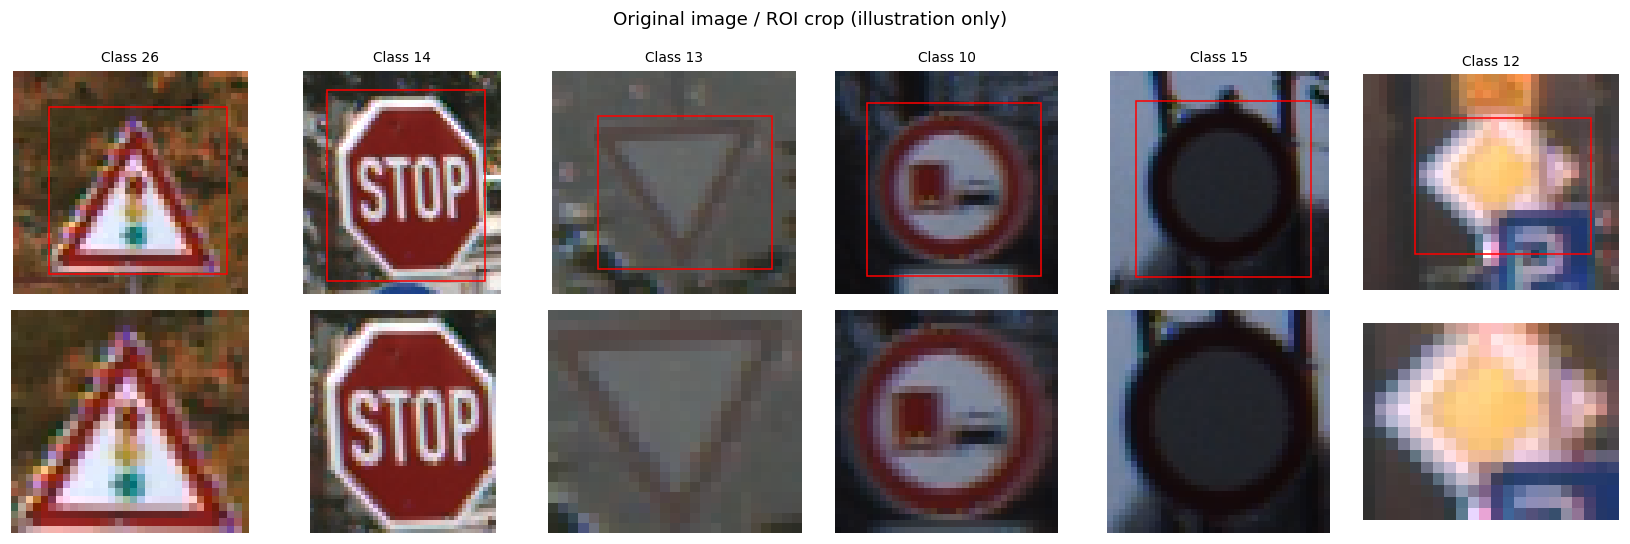

In [11]:
# Chỉ minh họa crop ROI, không sửa ảnh gốc. Giả định X2/Y2 là pixel cuối (inclusive).
# Cần đối chiếu quy ước biên của nguồn dữ liệu trước khi dùng crop trong preprocessing.
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for col, (_, row) in enumerate(train.sample(6, random_state=SEED).iterrows()):
    with Image.open(DATA_DIR / row['Path']) as original:
        image = original.convert('RGB')
        x1, y1, x2, y2 = [int(row[c]) for c in ['Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2']]
        axes[0, col].imshow(image)
        axes[0, col].add_patch(plt.Rectangle((x1,y1), x2-x1+1, y2-y1+1, fill=False, edgecolor='red'))
        crop = image.crop((x1, y1, min(x2+1,image.width), min(y2+1,image.height)))
        axes[1, col].imshow(crop)
        axes[0, col].set_title(f'Class {int(row.ClassId)}', fontsize=9)
    axes[0, col].axis('off')
    axes[1, col].axis('off')
fig.suptitle('Original image / ROI crop (illustration only)')
plt.tight_layout()
savefig('07_roi_examples')
plt.show()


## 5. Quét ảnh thật, độ sáng và độ tương phản

Giải mã ảnh để tìm ảnh không đọc được, kiểm tra kích thước và chế độ màu. Độ sáng là trung bình grayscale; độ tương phản là độ lệch chuẩn grayscale trên thumbnail tối đa 64 × 64.

Các chỉ số này chỉ mô tả ảnh, không phải đánh giá chất lượng tuyệt đối hoặc phép đo độ mờ. Ngưỡng tối/sáng/ít tương phản phục vụ chọn ảnh để xem, **không tự động xóa dữ liệu**.

SHA-256 của kích thước và pixel RGB dùng để tìm ảnh trùng pixel chính xác; không phát hiện đầy đủ ảnh gần trùng hay các khung hình liên tiếp.


Quét ảnh chạy song song với `IMAGE_SCAN_WORKERS = 8`; có thể giảm xuống 1 nếu ổ đĩa hoặc môi trường không phù hợp.


In [12]:
if FULL_IMAGE_SCAN:
    scan = data.copy()
else:
    # Lấy mẫu riêng từng lớp trong từng split; min() tránh lỗi lớp ít mẫu.
    chosen = [group.sample(min(len(group), QUICK_SAMPLES_PER_CLASS), random_state=SEED)
              for _, group in data.groupby(['Split', 'ClassId'])]
    scan = pd.concat(chosen, ignore_index=True)
def inspect_image(row):
    result = dict(Path=row.Path, Split=row.Split, ClassId=row.ClassId, ReadOK=False,
                  ActualWidth=np.nan, ActualHeight=np.nan, OriginalMode=None,
                  Brightness=np.nan, Contrast=np.nan, PixelHash=None, Error='')
    try:
        with Image.open(DATA_DIR / row.Path) as original:
            result['OriginalMode'] = original.mode
            image = original.convert('RGB')
            result['ActualWidth'], result['ActualHeight'] = image.size
            content = f'{image.width}x{image.height}:RGB:'.encode() + image.tobytes()
            result['PixelHash'] = hashlib.sha256(content).hexdigest()
            image.thumbnail((64,64), Image.Resampling.LANCZOS)
            gray = np.asarray(ImageOps.grayscale(image), dtype=np.float32)
            result['Brightness'], result['Contrast'] = float(gray.mean()), float(gray.std())
            result['ReadOK'] = True
    except (OSError, ValueError, SyntaxError) as exc:
        result['Error'] = f'{type(exc).__name__}: {exc}'
    return result

# Đọc theo đường dẫn giúp tăng tính cục bộ; map() giữ thứ tự kết quả ổn định.
scan = scan.sort_values(['Split', 'Path']).reset_index(drop=True)
with ThreadPoolExecutor(max_workers=IMAGE_SCAN_WORKERS) as pool:
    records = list(tqdm(pool.map(inspect_image, scan.itertuples(index=False)),
                        total=len(scan), desc='Inspecting images', mininterval=1.0))
metrics = pd.DataFrame(records).merge(data[['Path','Split','Width','Height']],
                                     on=['Path','Split'], how='left', validate='one_to_one')
metrics['SizeMismatch'] = metrics['ReadOK'] & ((metrics['ActualWidth'] != metrics['Width'])
                                              | (metrics['ActualHeight'] != metrics['Height']))
metrics['IsDark'] = metrics['ReadOK'] & metrics['Brightness'].lt(DARK_THRESHOLD)
metrics['IsBright'] = metrics['ReadOK'] & metrics['Brightness'].gt(BRIGHT_THRESHOLD)
metrics['IsLowContrast'] = metrics['ReadOK'] & metrics['Contrast'].lt(LOW_CONTRAST_THRESHOLD)
metrics.to_csv(OUT / 'image_metrics.csv', index=False)
quality = metrics.groupby('Split').agg(Scanned=('Path','size'), Readable=('ReadOK','sum'),
    SizeMismatches=('SizeMismatch','sum'), Dark=('IsDark','sum'), Bright=('IsBright','sum'),
    LowContrast=('IsLowContrast','sum'))
quality['Unreadable'] = quality['Scanned'] - quality['Readable']
quality.to_csv(OUT / 'quality_summary.csv')
display(quality)
display(metrics['OriginalMode'].value_counts().rename_axis('Mode').to_frame('Images'))
image_issues = metrics.loc[~metrics['ReadOK'] | metrics['SizeMismatch']]
image_issues.to_csv(OUT / 'image_issues.csv', index=False)
display(image_issues.head(10))


Inspecting images:   0%|          | 0/51839 [00:00<?, ?it/s]

,Scanned,Readable,SizeMismatches,Dark,Bright,LowContrast,Unreadable
Split,,,,,,,
Test,12630,12630,0,2694,85,2931,0
Train,39209,39209,0,8564,283,9489,0


,Images
Mode,
RGB,51839


,Path,Split,ClassId,ReadOK,ActualWidth,ActualHeight,OriginalMode,Brightness,Contrast,PixelHash,Error,Width,Height,SizeMismatch,IsDark,IsBright,IsLowContrast


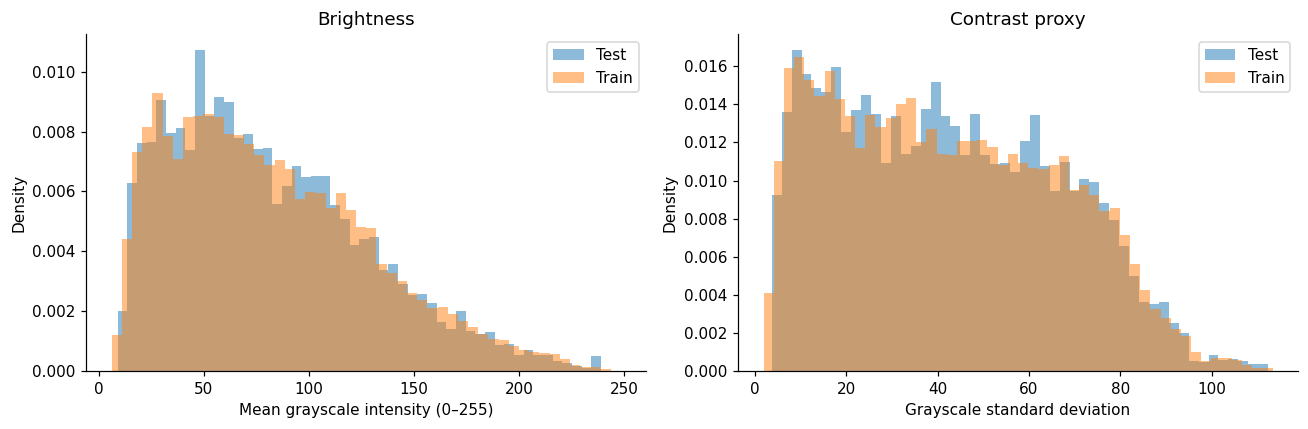

,Scanned,MeanBrightness,MeanContrast,DarkFraction,LowContrastFraction
ClassId,,,,,
0,210,122.673,52.042,0.000,0.014
1,2220,108.044,49.150,0.044,0.104
2,2250,92.845,48.374,0.081,0.130
3,1410,67.211,41.230,0.332,0.350
4,1980,69.425,37.601,0.335,0.340
5,1860,59.039,33.396,0.359,0.352
6,420,40.250,21.119,0.519,0.679
7,1440,58.481,30.827,0.359,0.365
8,1410,46.907,28.966,0.525,0.494


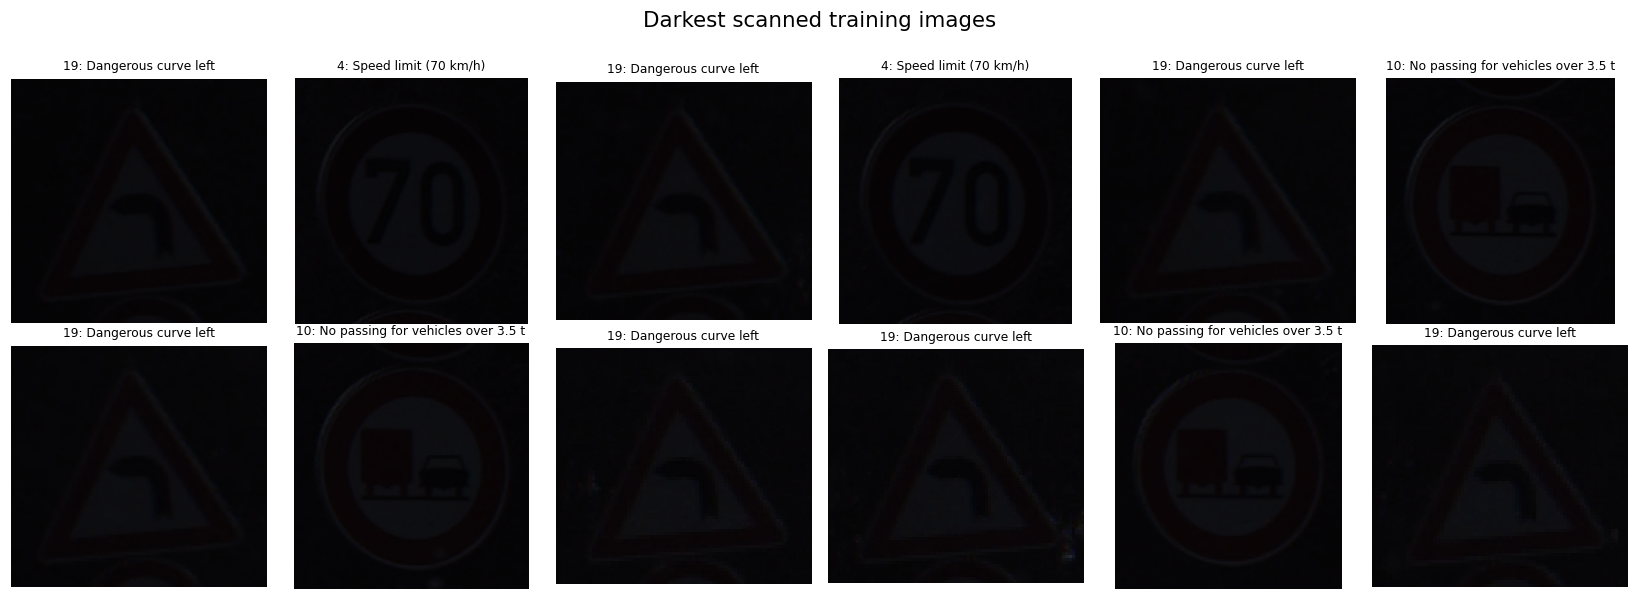

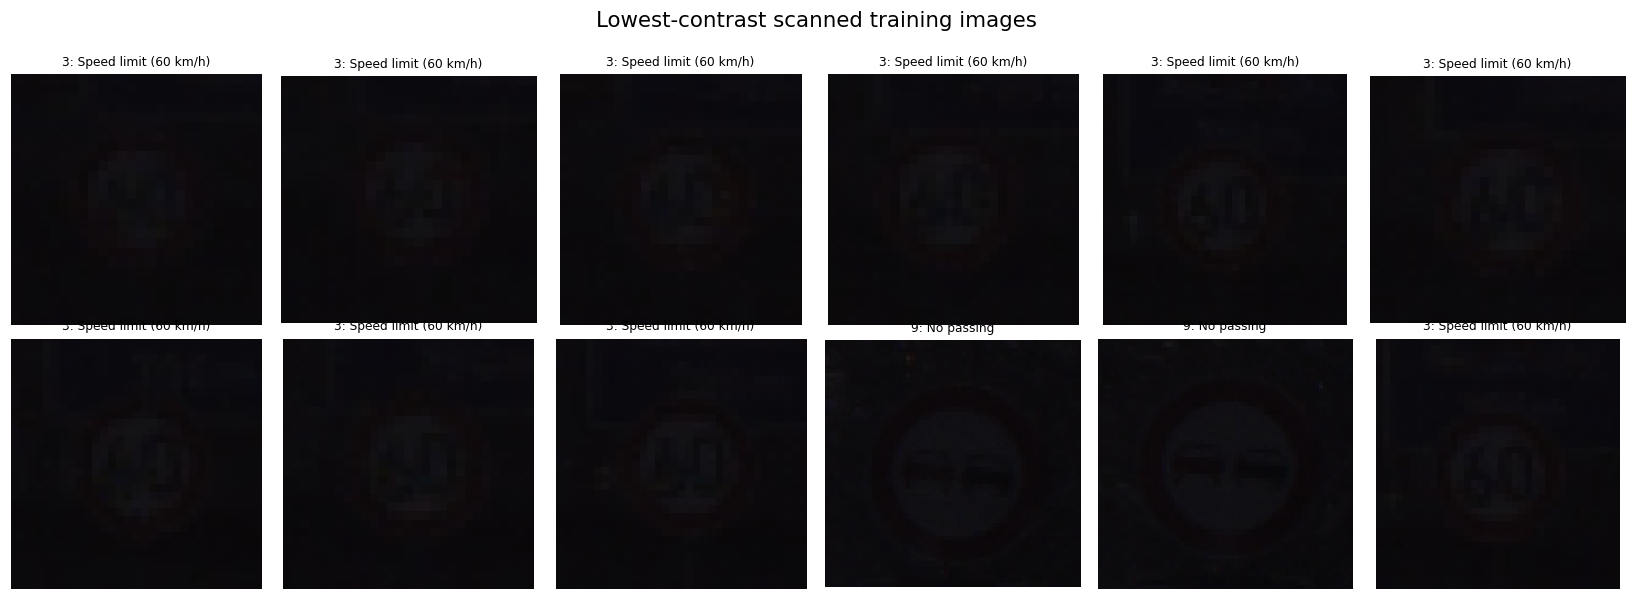

In [13]:
valid_metrics = metrics.loc[metrics['ReadOK']].copy()
assert not valid_metrics.empty, 'Không đọc được ảnh; xem image_issues.csv'
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for split, df in valid_metrics.groupby('Split'):
    axes[0].hist(df['Brightness'], bins=50, density=True, alpha=.5, label=split)
    axes[1].hist(df['Contrast'], bins=50, density=True, alpha=.5, label=split)
axes[0].set(xlabel='Mean grayscale intensity (0–255)', ylabel='Density', title='Brightness')
axes[1].set(xlabel='Grayscale standard deviation', ylabel='Density', title='Contrast proxy')
for ax in axes: ax.legend()
plt.tight_layout()
savefig('08_brightness_contrast')
plt.show()
train_metrics = valid_metrics.loc[valid_metrics['Split'].eq('Train')]
by_class = train_metrics.groupby('ClassId').agg(Scanned=('Path','size'),
    MeanBrightness=('Brightness','mean'), MeanContrast=('Contrast','mean'),
    DarkFraction=('IsDark','mean'), LowContrastFraction=('IsLowContrast','mean'))
by_class.to_csv(OUT / 'train_quality_by_class.csv')
display(by_class.round(3))
image_grid(train_metrics.nsmallest(12,'Brightness'), 'Darkest scanned training images', output_name='09_dark_examples')
image_grid(train_metrics.nsmallest(12,'Contrast'), 'Lowest-contrast scanned training images', output_name='10_low_contrast_examples')


## 6. Ảnh trùng pixel chính xác và nhãn mâu thuẫn

Báo cáo ảnh trùng trong một tập, trùng giữa train/test và cùng pixel nhưng khác nhãn. Không tự động xóa ảnh/đổi nhãn. Nếu có, cần xem xét trước khi huấn luyện và ghi rõ phương án xử lý. Không trộn test vào train.

Nếu chỉ chạy mẫu, không có ảnh trùng trong mẫu chưa chứng minh toàn bộ dữ liệu không có ảnh trùng.


Nhóm trùng pixel: 8 | Ảnh thuộc nhóm trùng: 16
Số bản dư nếu giữ một ảnh mỗi nhóm: 8
Nhóm trùng train/test: 8 | Nhóm có nhãn mâu thuẫn: 0


,Split,ClassId,Path,PixelHash
9575,Test,14,Test/09575.png,125b62a3a7a37fe0c218b1c6c397a853c348e6d5a8b8c9...
23356,Train,14,Train/14/00014_00023_00016.png,125b62a3a7a37fe0c218b1c6c397a853c348e6d5a8b8c9...
3594,Test,14,Test/03594.png,303d15f406f6c5c6c8a84960604dc7c511afe2720662ab...
23350,Train,14,Train/14/00014_00023_00010.png,303d15f406f6c5c6c8a84960604dc7c511afe2720662ab...
4548,Test,14,Test/04548.png,37790e11faa7d4a952542c8a03efd4d39ec331cf88cb99...
23346,Train,14,Train/14/00014_00023_00006.png,37790e11faa7d4a952542c8a03efd4d39ec331cf88cb99...
11906,Test,14,Test/11906.png,64c77ac2d9491265a825236bfc5c4e58ab19ea96a54a9e...
23343,Train,14,Train/14/00014_00023_00003.png,64c77ac2d9491265a825236bfc5c4e58ab19ea96a54a9e...
666,Test,14,Test/00666.png,6be2235715f648e5a27c7c91fdbffddecec20bb63d4008...
23359,Train,14,Train/14/00014_00023_00019.png,6be2235715f648e5a27c7c91fdbffddecec20bb63d4008...


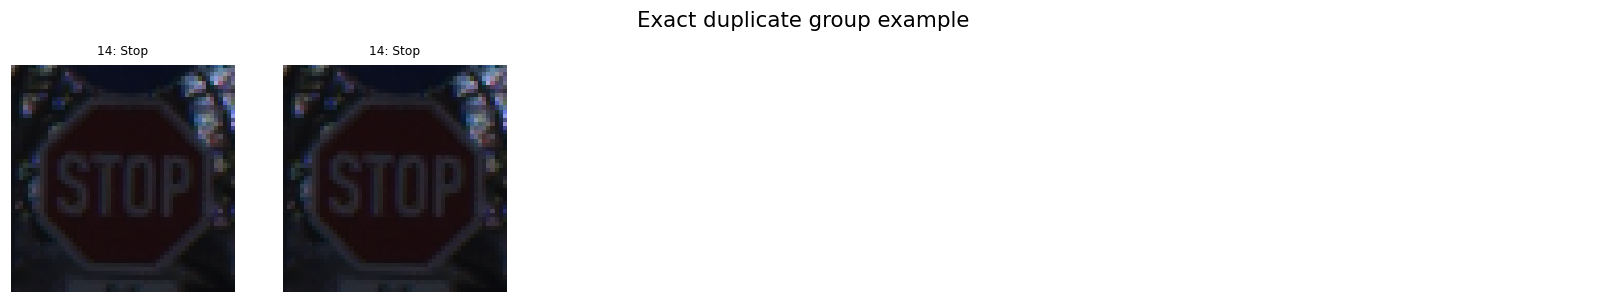

In [14]:
hashes = valid_metrics.groupby('PixelHash').agg(Images=('Path','size'), Splits=('Split','nunique'), Labels=('ClassId','nunique'))
dup_keys = hashes.index[hashes['Images'].gt(1)]
cross_keys = hashes.index[hashes['Splits'].gt(1)]
conflict_keys = hashes.index[hashes['Labels'].gt(1)]
duplicates = valid_metrics.loc[valid_metrics['PixelHash'].isin(dup_keys)].sort_values('PixelHash')
for keys, name in [(dup_keys, 'exact_duplicate_images'), (cross_keys, 'cross_split_duplicate_images'),
                   (conflict_keys, 'conflicting_label_images')]:
    valid_metrics.loc[valid_metrics['PixelHash'].isin(keys)].sort_values('PixelHash').to_csv(OUT / f'{name}.csv', index=False)
print('Nhóm trùng pixel:', len(dup_keys), '| Ảnh thuộc nhóm trùng:', len(duplicates))
print('Số bản dư nếu giữ một ảnh mỗi nhóm:', int((hashes['Images']-1).clip(lower=0).sum()))
print('Nhóm trùng train/test:', len(cross_keys), '| Nhóm có nhãn mâu thuẫn:', len(conflict_keys))
display(duplicates[['Split','ClassId','Path','PixelHash']].head(12))
if len(dup_keys):
    image_grid(duplicates[duplicates['PixelHash'].eq(dup_keys[0])].head(12),
               'Exact duplicate group example', output_name='11_exact_duplicates')


## 7. Nhóm ảnh và rủi ro khi chia validation

Kiểm tra tên ảnh theo mẫu `class_track_frame.png`. Khóa nhóm dưới đây **suy ra từ tên tệp**; cần quan sát và xác nhận ý nghĩa nhóm trước khi dùng để chia tập.

Nếu một nhóm gồm các ảnh liên tiếp gần giống nhau, chia ngẫu nhiên từng ảnh có thể làm validation quá dễ. Xem xét chia theo nhóm, giữ phân bố lớp và kiểm tra cả trùng pixel giữa train/validation. Notebook chưa chia dữ liệu.


Tên ảnh khớp mẫu: 39,209/39,209


,Candidate group sizes
count,1307.000000
mean,29.999235
std,0.027661
min,29.000000
25%,30.000000
50%,30.000000
75%,30.000000
max,30.000000


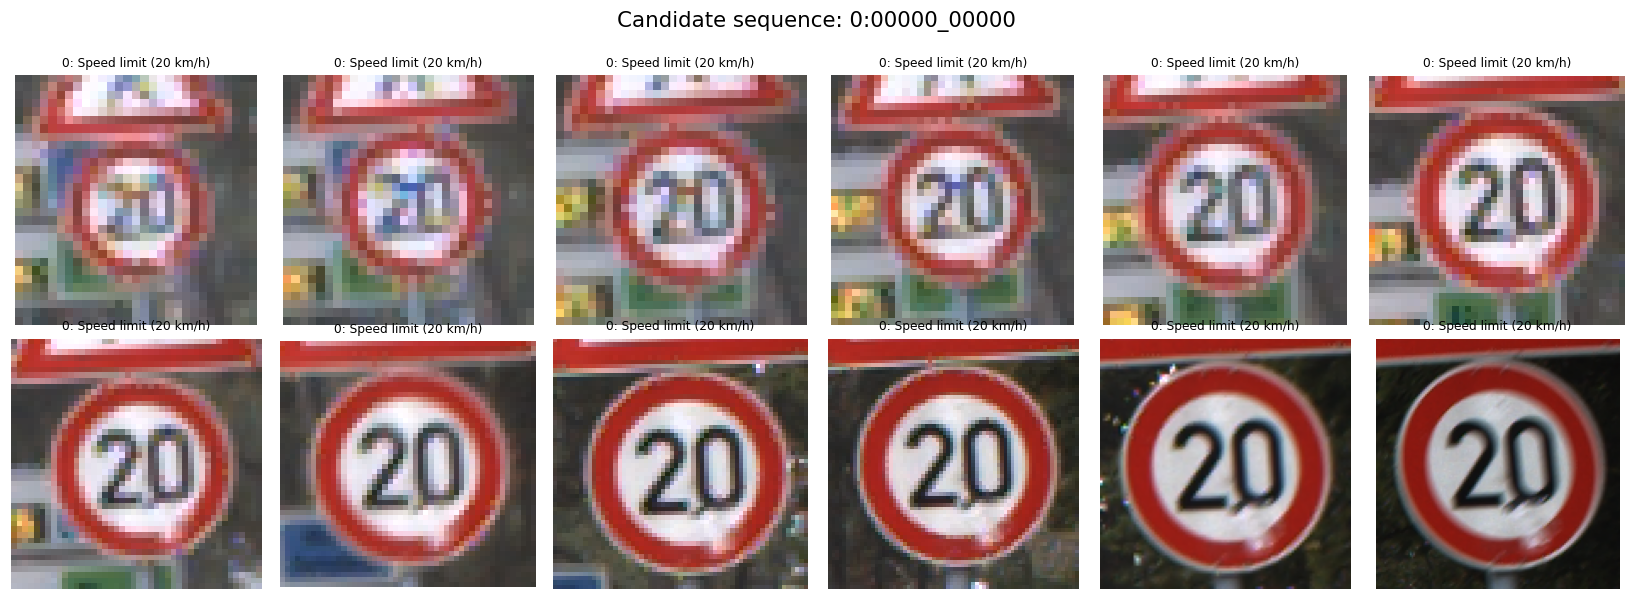

In [15]:
parsed = train['Path'].map(lambda p: re.fullmatch(r'(\d+)_(\d+)_(\d+)', Path(p).stem))
train['CandidateGroup'] = [f'{int(cid)}:{m.group(1)}_{m.group(2)}' if m else None
                           for cid, m in zip(train['ClassId'], parsed)]
train['FrameIndex'] = [int(m.group(3)) if m else np.nan for m in parsed]
print(f'Tên ảnh khớp mẫu: {train["CandidateGroup"].notna().sum():,}/{len(train):,}')
group_sizes = train.dropna(subset=['CandidateGroup']).groupby(['ClassId','CandidateGroup']).size().rename('Images')
group_sizes.to_csv(OUT / 'candidate_group_sizes.csv')
train.groupby('ClassId')['CandidateGroup'].nunique().rename('CandidateGroups').to_csv(OUT / 'candidate_groups_per_class.csv')
display(group_sizes.describe().to_frame('Candidate group sizes'))
if not group_sizes.empty:
    group_id = group_sizes.idxmax()[1]
    sequence = train.loc[train['CandidateGroup'].eq(group_id)].sort_values('FrameIndex')
    positions = np.linspace(0,len(sequence)-1,min(12,len(sequence)),dtype=int)
    image_grid(sequence.iloc[positions], f'Candidate sequence: {group_id}', output_name='12_candidate_sequence')


## 8. Tổng hợp kết quả và phương án tiền xử lý

Bản tổng hợp được tạo từ kết quả chạy thực tế. Các phương án resize, crop ROI, cân bằng lớp và augmentation là giả thuyết cần kiểm chứng trên validation, chưa phải kết luận về hiệu năng.


In [16]:
summary = dict(source='https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign',
    seed=SEED, full_scan=FULL_IMAGE_SCAN, image_scan_workers=IMAGE_SCAN_WORKERS, train_images=len(train), test_images=len(test),
    classes=int(train['ClassId'].nunique()), train_imbalance_ratio=float(imbalance_ratio),
    scanned_images=len(metrics), unreadable_images=int((~metrics['ReadOK']).sum()),
    metadata_size_mismatches=int(metrics['SizeMismatch'].sum()), metadata_anomalies=len(metadata_issues),
    exact_duplicate_groups=len(dup_keys), cross_split_duplicate_groups=len(cross_keys),
    conflicting_label_groups=len(conflict_keys), candidate_train_groups=int(train['CandidateGroup'].nunique()),
    quality_thresholds=dict(dark_below=DARK_THRESHOLD, bright_above=BRIGHT_THRESHOLD,
                            low_contrast_below=LOW_CONTRAST_THRESHOLD), versions=VERSIONS)
(OUT / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
report = f"""# Tổng hợp EDA GTSRB

- Train: {len(train):,} ảnh; test: {len(test):,} ảnh; {summary['classes']} lớp.
- Tỷ lệ số mẫu train giữa lớp lớn nhất/nhỏ nhất: {imbalance_ratio:.2f} lần.
- Đã quét {len(metrics):,} ảnh. Quét đầy đủ: {FULL_IMAGE_SCAN}.
- Ảnh không đọc được: {summary['unreadable_images']}; sai kích thước so với CSV: {summary['metadata_size_mismatches']}.
- Metadata mô tả bị thiếu: {int(meta.isna().sum().sum())} giá trị; xem missing_values_by_column.csv.
- Metadata có kích thước/ROI bất thường: {len(metadata_issues)} dòng.
- Nhóm trùng pixel: {len(dup_keys)}; trùng train/test: {len(cross_keys)}; nhãn mâu thuẫn: {len(conflict_keys)}.
- Nhóm ảnh ứng viên suy ra từ tên tệp train: {summary['candidate_train_groups']}.

## Việc cần thực hiện trước huấn luyện

1. Xem ảnh lỗi, metadata bất thường, ảnh trùng và nhãn mâu thuẫn nếu có. Không tự động xóa ảnh.
2. Giữ test riêng; chia validation từ train. Xác nhận nhóm ảnh và xem xét chia theo nhóm; kiểm tra trùng pixel giữa các tập mới.
3. Giữ RGB; chọn resize và chuẩn hóa phù hợp CNN hoặc trọng số VGG16. Thống kê chuẩn hóa và trọng số lớp chỉ tính từ train sau khi chia.
4. Huấn luyện CNN cơ sở với xử lý tối thiểu trước. Sau đó thử augmentation nhẹ trên train; tránh lật hướng hoặc cắt mất ký hiệu.
5. Báo cáo accuracy, macro-F1, recall từng lớp và confusion matrix. Nếu cần, thử class weighting riêng để đo tác dụng.
6. Ảnh tối, sáng hoặc ít tương phản vẫn có thể hợp lệ. Ngưỡng EDA không phải quy tắc loại bỏ ảnh.

Hash chỉ phát hiện ảnh trùng pixel chính xác. Nếu chạy mẫu, cần quét lại toàn bộ trước khi kết luận.
"""
(OUT / 'eda_summary.md').write_text(report, encoding='utf-8')
display(Markdown(report))
print('Đã lưu các bảng và summary:', OUT)
print('Đã lưu biểu đồ:', FIG)


# Tổng hợp EDA GTSRB

- Train: 39,209 ảnh; test: 12,630 ảnh; 43 lớp.
- Tỷ lệ số mẫu train giữa lớp lớn nhất/nhỏ nhất: 10.71 lần.
- Đã quét 51,839 ảnh. Quét đầy đủ: True.
- Ảnh không đọc được: 0; sai kích thước so với CSV: 0.
- Metadata mô tả bị thiếu: 1 giá trị; xem missing_values_by_column.csv.
- Metadata có kích thước/ROI bất thường: 0 dòng.
- Nhóm trùng pixel: 8; trùng train/test: 8; nhãn mâu thuẫn: 0.
- Nhóm ảnh ứng viên suy ra từ tên tệp train: 1307.

## Việc cần thực hiện trước huấn luyện

1. Xem ảnh lỗi, metadata bất thường, ảnh trùng và nhãn mâu thuẫn nếu có. Không tự động xóa ảnh.
2. Giữ test riêng; chia validation từ train. Xác nhận nhóm ảnh và xem xét chia theo nhóm; kiểm tra trùng pixel giữa các tập mới.
3. Giữ RGB; chọn resize và chuẩn hóa phù hợp CNN hoặc trọng số VGG16. Thống kê chuẩn hóa và trọng số lớp chỉ tính từ train sau khi chia.
4. Huấn luyện CNN cơ sở với xử lý tối thiểu trước. Sau đó thử augmentation nhẹ trên train; tránh lật hướng hoặc cắt mất ký hiệu.
5. Báo cáo accuracy, macro-F1, recall từng lớp và confusion matrix. Nếu cần, thử class weighting riêng để đo tác dụng.
6. Ảnh tối, sáng hoặc ít tương phản vẫn có thể hợp lệ. Ngưỡng EDA không phải quy tắc loại bỏ ảnh.

Hash chỉ phát hiện ảnh trùng pixel chính xác. Nếu chạy mẫu, cần quét lại toàn bộ trước khi kết luận.


Đã lưu các bảng và summary: /content/outputs/eda
Đã lưu biểu đồ: /content/outputs/eda/figures
